
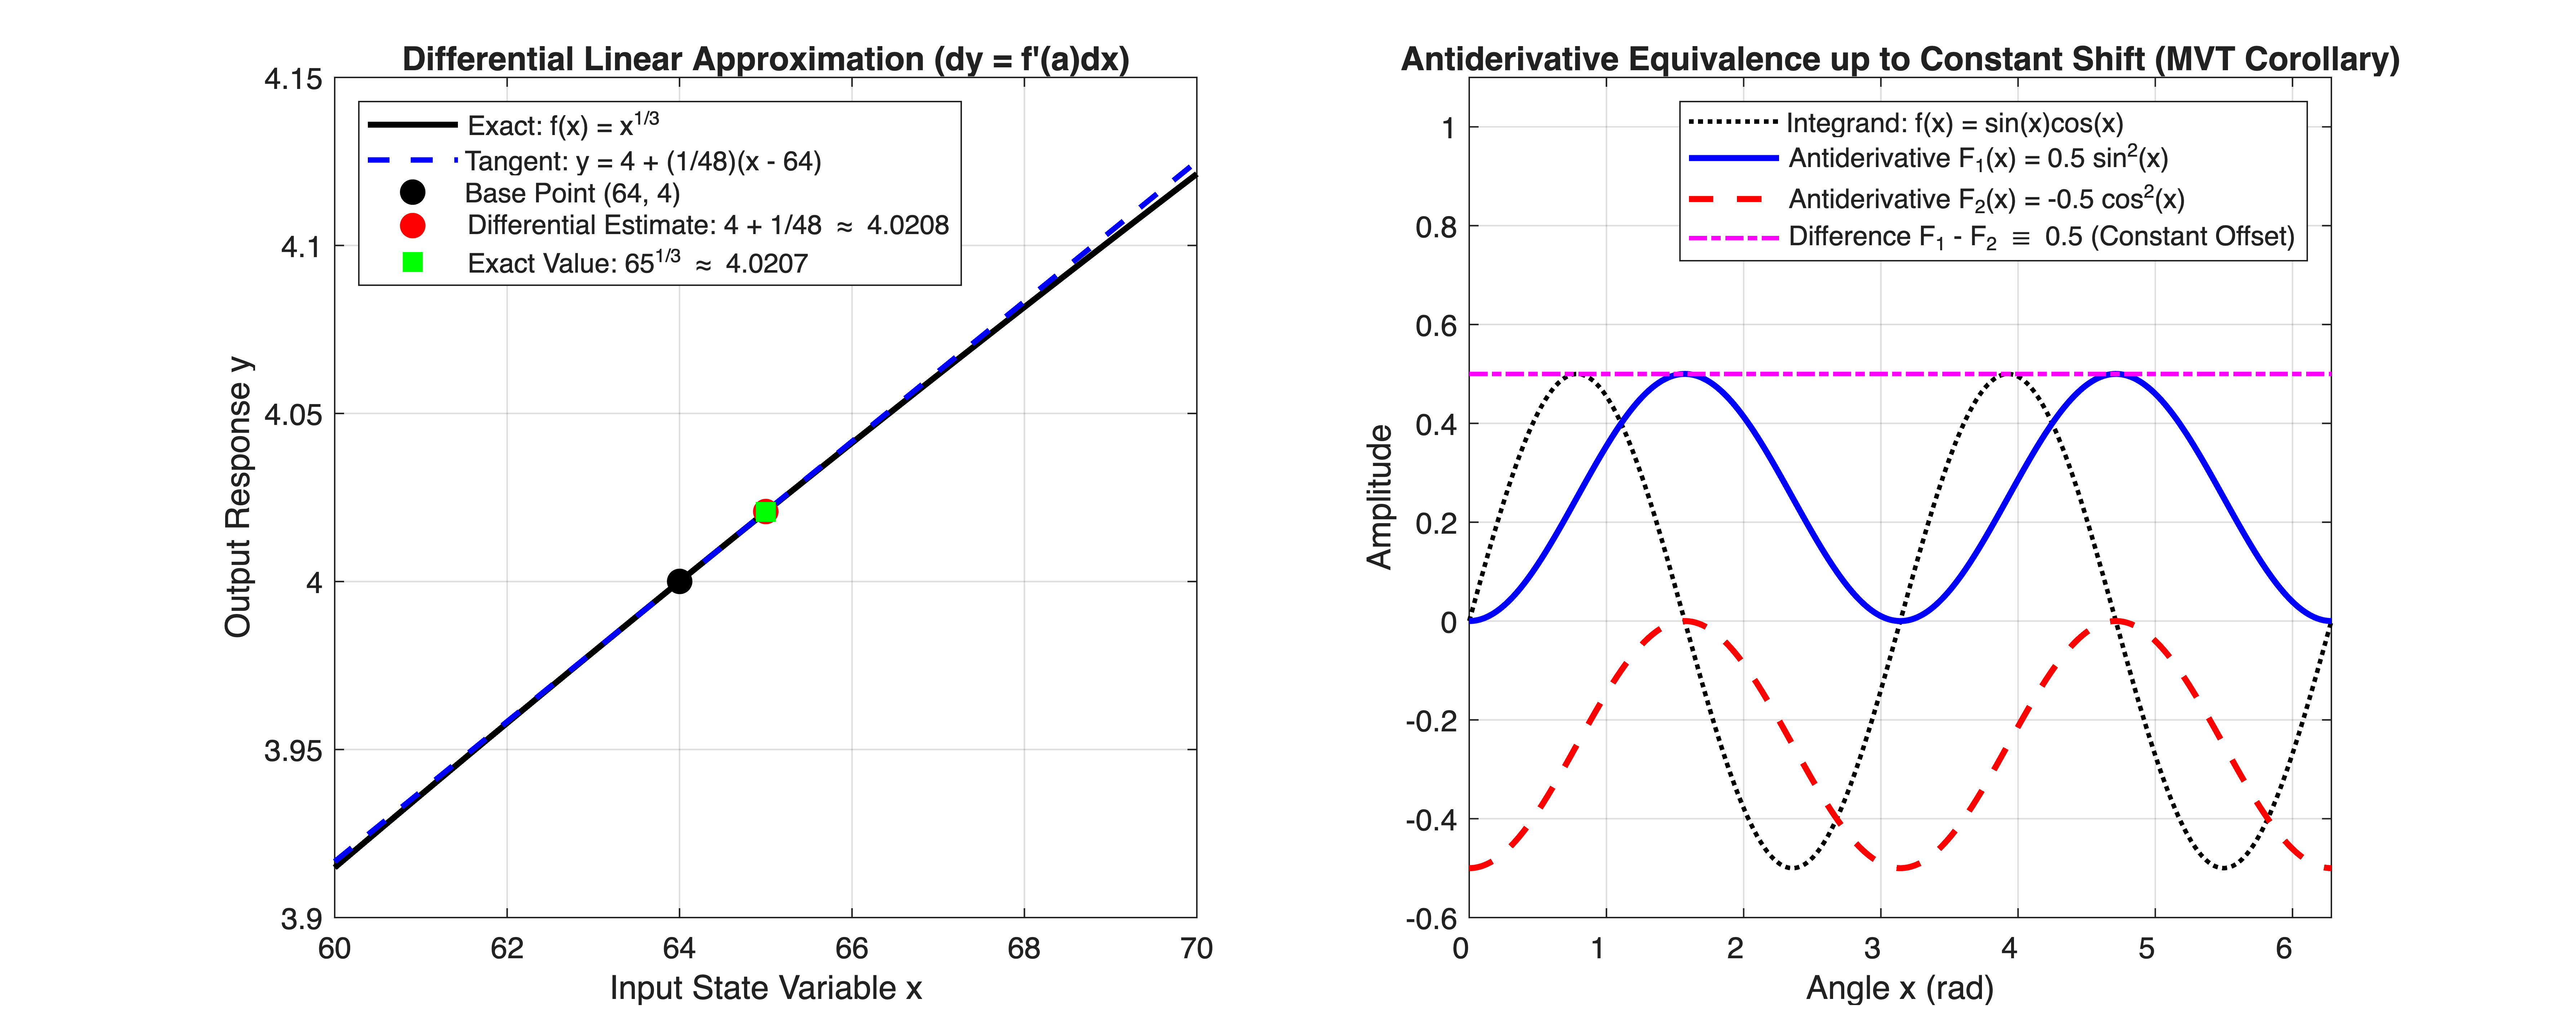

In [1]:
%% MIT 18.01 Lecture 15: Differentials Approximation & Antiderivative Field
% Mathematical Tool Application: Used for discrete incremental state stepping,
% initial condition configuration for continuous integration blocks (1/s),
% and coordinate transformation (u-substitution) in energy integral formulation.


clear; clc; close all;


%% Part 1: Differential Linear Approximation of f(x) = x^(1/3) near x = 64
% Base operating point: a = 64 => f(a) = 4, f'(a) = (1/3)*(64)^(-2/3) = 1/48
a = 64.0;
f_base = a^(1/3);
df_base = (1/3) * a^(-2/3); % 1 / 48 approx 0.020833


% Continuous curve span
x_span = linspace(60, 70, 300);
y_exact = x_span.^(1/3);
y_differential = f_base + df_base * (x_span - a);


% Target evaluation point from Lecture 15: x = 65 (dx = 1)
x_target = 65.0;
dx_target = x_target - a;
dy_approx = df_base * dx_target;
y_approx_target = f_base + dy_approx; % 4 + 1/48 approx 4.020833
y_exact_target = x_target^(1/3);


figure('Color', 'w', 'Position', [100, 100, 1200, 480]);


subplot(1, 2, 1);
plot(x_span, y_exact, 'k-', 'LineWidth', 2.0, 'DisplayName', 'Exact: f(x) = x^{1/3}'); hold on;
plot(x_span, y_differential, 'b--', 'LineWidth', 1.8, 'DisplayName', 'Tangent: y = 4 + (1/48)(x - 64)');
plot(a, f_base, 'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'k', 'DisplayName', 'Base Point (64, 4)');
plot(x_target, y_approx_target, 'ro', 'MarkerSize', 8, 'MarkerFaceColor', 'r', ...
    'DisplayName', sprintf('Differential Estimate: 4 + 1/48 \\approx %.4f', y_approx_target));
plot(x_target, y_exact_target, 'gs', 'MarkerSize', 8, 'MarkerFaceColor', 'g', ...
    'DisplayName', sprintf('Exact Value: 65^{1/3} \\approx %.4f', y_exact_target));


grid on;
xlim([60, 70]); ylim([3.9, 4.15]);
xlabel('Input State Variable x');
ylabel('Output Response y');
title('Differential Linear Approximation (dy = f''(a)dx)');
legend('Location', 'northwest');


%% Part 2: Antiderivative Family & Constant Offset: \int sin(x)cos(x)dx
% Lecture Example 5: F1(x) = 0.5*sin(x)^2 vs F2(x) = -0.5*cos(x)^2
% Identity: F1(x) - F2(x) = 0.5*(sin^2(x) + cos^2(x)) = 0.5 (Constant Shift)
x_trig = linspace(0, 2*pi, 400);
integrand_f = sin(x_trig) .* cos(x_trig); % 0.5*sin(2x)
F1 = 0.5 * (sin(x_trig).^2);
F2 = -0.5 * (cos(x_trig).^2);


subplot(1, 2, 2);
plot(x_trig, integrand_f, 'k:', 'LineWidth', 1.5, 'DisplayName', 'Integrand: f(x) = sin(x)cos(x)'); hold on;
plot(x_trig, F1, 'b-', 'LineWidth', 2.0, 'DisplayName', 'Antiderivative F_1(x) = 0.5 sin^2(x)');
plot(x_trig, F2, 'r--', 'LineWidth', 2.0, 'DisplayName', 'Antiderivative F_2(x) = -0.5 cos^2(x)');
plot(x_trig, F1 - F2, 'm-.', 'LineWidth', 1.5, 'DisplayName', 'Difference F_1 - F_2 \equiv 0.5 (Constant Offset)');


grid on;
xlim([0, 2*pi]); ylim([-0.6, 1.1]);
xlabel('Angle x (rad)');
ylabel('Amplitude');
title('Antiderivative Equivalence up to Constant Shift (MVT Corollary)');
legend('Location', 'northeast');